In [ ]:
import kagglehub
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print(path)

Using Colab cache for faster access to the 'creditcardfraud' dataset.
/kaggle/input/creditcardfraud


In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv("/kaggle/input/creditcardfraud/creditcard.csv")

In [ ]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


In [ ]:
duplicates = df[df.duplicated(keep=False)].sort_values(
    by=['Time','Amount']
)

df.drop_duplicates(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['Class'].value_counts(normalize=True)

,proportion
Class,
0,0.998333
1,0.001667


### Dataset Information:
- Supervised Learning dataset
- Classification
- Highly imbalanced
- No missing values
- Some duplicates but removed

### Now as the dataset is imbalanced we will use some strategies for handling it:
1. Class Weights
2. Oversampling - SMOTE

### As this is Classification Supervised learning Problem, we will use following algorithms:
1. Random Forest
2. Logistic Regression
3. Gradient Boosting
4. Extreme Gradient Boosting
5. K-Nearest Neighbors

### We will working on the combination for these all algorithms and strategies.

### Data Preparation

In [ ]:
# Seperating the Columns

X = df.iloc[:, :-1]
y = df["Class"]

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
# Training vs Temporary

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size = 0.3,
    random_state = 42,
    stratify = y
)

In [ ]:
# Validation vs Testing

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size = 0.50,
    random_state = 42,
    stratify = y_temp
)

In [ ]:
print(X.shape, X_train.shape, X_val.shape, X_test.shape)
print(y.shape, y_train.shape, y_val.shape, y_test.shape)

(283726, 30) (198608, 30) (42559, 30) (42559, 30)
(283726,) (198608,) (42559,) (42559,)


### Defining the Cross Validation for Screening

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [ ]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

In [ ]:
scoring = {
    "PR-AUC": "average_precision",
    "F1": "f1",
    "Precision": "precision",
    "Recall": "recall"
}

### RANDOM FOREST

In [ ]:
from sklearn.pipeline import Pipeline

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
# Random Forest

rf = Pipeline([
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=1,
    ))
])

In [ ]:
rf_cv = cross_validate(
    rf,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [ ]:
rf_cv

{'fit_time': array([264.25021434, 270.12585497, 208.1547761 ]),
 'score_time': array([1.64877868, 1.76162052, 0.99498272]),
 'test_PR-AUC': array([0.83105117, 0.82973389, 0.83756558]),
 'test_F1': array([0.82926829, 0.85148515, 0.87437186]),
 'test_Precision': array([0.89473684, 0.94505495, 0.97752809]),
 'test_Recall': array([0.77272727, 0.77477477, 0.79090909])}

In [ ]:
rf_cv_results = pd.DataFrame([{
    "Model": "Random Forest",
    "PR-AUC Mean": rf_cv['test_PR-AUC'].mean(),
    "PR-AUC Std": rf_cv["test_PR-AUC"].std(),
    "F1 Mean": rf_cv["test_F1"].mean(),
    "F1 Std": rf_cv["test_F1"].std(),
    "Precision Mean": rf_cv['test_Precision'].mean(),
    "Precision Std": rf_cv['test_Precision'].std(),
    "Recall Mean": rf_cv['test_Recall'].mean(),
    "Recall Std": rf_cv['test_Recall'].std()
}])

In [ ]:
results = rf_cv_results
results

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Random Forest,0.832784,0.003424,0.851708,0.018414,0.939107,0.03406,0.77947,0.008131


### We calculate mean for `how good the model performs` and std for `how consistent is the model performance` ?

In [ ]:
# Random Forest with Class Weights adjusted

rf_cw = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)


In [ ]:
rf_cw_cv = cross_validate(
    rf_cw,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [ ]:
rf_cw_cv

{'fit_time': array([145.26706815, 150.43541145,  72.21007538]),
 'score_time': array([1.58576035, 1.46598291, 0.69691849]),
 'test_PR-AUC': array([0.83682021, 0.80558744, 0.84200666]),
 'test_F1': array([0.81818182, 0.84422111, 0.84536082]),
 'test_Precision': array([0.92045455, 0.95454545, 0.97619048]),
 'test_Recall': array([0.73636364, 0.75675676, 0.74545455])}

In [ ]:
rf_cw_cv_scores = pd.DataFrame([{
    "Model": "Random Forest With Class Weights",
    "PR-AUC Mean": rf_cw_cv["test_PR-AUC"].mean(),
    "PR-AUC Std": rf_cw_cv["test_PR-AUC"].std(),
    "F1 Mean": rf_cw_cv['test_F1'].mean(),
    "F1 Std": rf_cw_cv['test_F1'].std(),
    "Precision Mean": rf_cw_cv['test_Precision'].mean(),
    "Precision Std": rf_cw_cv['test_Precision'].std(),
    "Recall Mean": rf_cw_cv['test_Recall'].mean(),
    "Recall Std": rf_cw_cv['test_Recall'].std()
}])

In [ ]:
rf_cw_cv_scores

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Random Forest With Class Weights,0.828138,0.016086,0.835921,0.012552,0.950397,0.022942,0.746192,0.008342


In [ ]:
results = pd.concat([results, rf_cw_cv_scores], ignore_index=True)
results

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Random Forest,0.832784,0.003424,0.851708,0.018414,0.939107,0.034060,0.779470,0.008131
1,Random Forest With Class Weights,0.828138,0.016086,0.835921,0.012552,0.950397,0.022942,0.746192,0.008342


### Whenever Resampling is to be done, we use the pipeline from the Imblearn library which is for imbalanced datasets. This is because it applies the sampling technique to the training data but not on the testing data.

In [ ]:
# Random Forest with SMOTE

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [ ]:
rf_smote = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

In [ ]:
rf_smote_cv = cross_validate(
    rf_smote,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [ ]:
rf_smote_cv_scores = pd.DataFrame([{
    "Model": "Random Forest With Smote",
    "PR-AUC Mean": rf_smote_cv['test_PR-AUC'].mean(),
    "PR-AUC Std": rf_smote_cv['test_PR-AUC'].std(),
    "F1 Mean": rf_smote_cv['test_F1'].mean(),
    "F1 Std": rf_smote_cv['test_F1'].std(),
    "Precision Mean": rf_smote_cv['test_F1'].mean(),
    "Precision Std": rf_smote_cv['test_F1'].std(),
    "Recall Mean": rf_smote_cv['test_Recall'].mean(),
    "Recall Std": rf_smote_cv['test_Recall'].std()
}])

In [ ]:
rf_smote_cv_scores

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Random Forest With Smote,0.842211,0.011034,0.856269,0.003308,0.856269,0.003308,0.836882,0.006797


In [ ]:
results = pd.concat([results, rf_smote_cv_scores], ignore_index=True)
results

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Random Forest,0.832784,0.003424,0.851708,0.018414,0.939107,0.034060,0.779470,0.008131
1,Random Forest With Class Weights,0.828138,0.016086,0.835921,0.012552,0.950397,0.022942,0.746192,0.008342
2,Random Forest With Smote,0.842211,0.011034,0.856269,0.003308,0.856269,0.003308,0.836882,0.006797


### LOGISTIC REGRESSION

- As Logistic Regression is `Gradient Based model` we will be having a scaler for its application.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

In [ ]:
lr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [ ]:
lr_cv = cross_validate(
    lr,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [ ]:
lr_cv_scores = pd.DataFrame([{
    "Model": "Logistic Regression",
    "PR-AUC Mean": lr_cv['test_PR-AUC'].mean(),
    "PR-AUC Std": lr_cv['test_PR-AUC'].std(),
    "F1 Mean": lr_cv['test_F1'].mean(),
    "F1 Std": lr_cv['test_F1'].std(),
    "Precision Mean": lr_cv['test_Precision'].mean(),
    "Precision Std": lr_cv['test_Precision'].std(),
    "Recall Mean": lr_cv['test_Recall'].mean(),
    "Recall Std": lr_cv['test_Recall'].std(),
}])

lr_cv_scores

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Logistic Regression,0.757639,0.027452,0.739911,0.02928,0.878951,0.051778,0.640377,0.031102


In [ ]:
results = pd.concat([results, lr_cv_scores], ignore_index=True)
results

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Random Forest,0.832784,0.003424,0.851708,0.018414,0.939107,0.034060,0.779470,0.008131
1,Random Forest With Class Weights,0.828138,0.016086,0.835921,0.012552,0.950397,0.022942,0.746192,0.008342
2,Random Forest With Smote,0.842211,0.011034,0.856269,0.003308,0.856269,0.003308,0.836882,0.006797
3,Logistic Regression,0.757639,0.027452,0.739911,0.029280,0.878951,0.051778,0.640377,0.031102


In [ ]:
# Logistic Regression with Class Weights

lr_cw = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

In [ ]:
lr_cw_cv = cross_validate(
    lr_cw,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [ ]:
lr_cw_cv_scores = pd.DataFrame([{
    "Model": "Logistic Regression with Class Weights",
    "PR-AUC Mean": lr_cw_cv['test_PR-AUC'].mean(),
    "PR-AUC Std": lr_cw_cv['test_PR-AUC'].std(),
    "F1 Mean": lr_cw_cv['test_F1'].mean(),
    "F1 Std": lr_cw_cv['test_F1'].std(),
    "Precision Mean": lr_cw_cv['test_Precision'].mean(),
    "Precision Std": lr_cw_cv['test_Precision'].std(),
    "Recall Mean": lr_cw_cv['test_Recall'].mean(),
    "Recall Std": lr_cw_cv['test_Recall'].std(),
}])

lr_cw_cv_scores

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Logistic Regression with Class Weights,0.747562,0.024749,0.102746,0.006111,0.054484,0.003505,0.906416,0.027799


In [ ]:
results = pd.concat([results, lr_cw_cv_scores], ignore_index=True)

results

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Random Forest,0.832784,0.003424,0.851708,0.018414,0.939107,0.034060,0.779470,0.008131
1,Random Forest With Class Weights,0.828138,0.016086,0.835921,0.012552,0.950397,0.022942,0.746192,0.008342
2,Random Forest With Smote,0.842211,0.011034,0.856269,0.003308,0.856269,0.003308,0.836882,0.006797
3,Logistic Regression,0.757639,0.027452,0.739911,0.029280,0.878951,0.051778,0.640377,0.031102
4,Logistic Regression with Class Weights,0.747562,0.024749,0.102746,0.006111,0.054484,0.003505,0.906416,0.027799


In [ ]:
# Logistic Regression with SMOTE

from imblearn.pipeline import Pipeline

lr_smote = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [ ]:
lr_smote_cv = cross_validate(
    lr_smote,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [ ]:
lr_smote_cv_scores = pd.DataFrame([{
    "Model": "Logistic Regression with SMOTE",
    "PR-AUC Mean": lr_smote_cv['test_PR-AUC'].mean(),
    "PR-AUC Std": lr_smote_cv['test_PR-AUC'].std(),
    "F1 Mean": lr_smote_cv['test_PR-AUC'].mean(),
    "F1 Std": lr_smote_cv['test_PR-AUC'].std(),
    "Precision Mean": lr_smote_cv['test_Precision'].mean(),
    "Precision Std": lr_smote_cv['test_Precision'].std(),
    "Recall Mean": lr_smote_cv['test_Recall'].mean(),
    "Recall Std": lr_smote_cv['test_Recall'].std()
}])

lr_smote_cv_scores

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Logistic Regression with SMOTE,0.746304,0.024162,0.746304,0.024162,0.050219,0.002291,0.906388,0.027929


Random Forest took so much time but Logistic Regression is so much fast

In [ ]:
results = pd.concat([results, lr_smote_cv_scores], ignore_index=True)

results

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Random Forest,0.832784,0.003424,0.851708,0.018414,0.939107,0.034060,0.779470,0.008131
1,Random Forest With Class Weights,0.828138,0.016086,0.835921,0.012552,0.950397,0.022942,0.746192,0.008342
2,Random Forest With Smote,0.842211,0.011034,0.856269,0.003308,0.856269,0.003308,0.836882,0.006797
3,Logistic Regression,0.757639,0.027452,0.739911,0.029280,0.878951,0.051778,0.640377,0.031102
4,Logistic Regression with Class Weights,0.747562,0.024749,0.102746,0.006111,0.054484,0.003505,0.906416,0.027799
5,Logistic Regression with SMOTE,0.746304,0.024162,0.746304,0.024162,0.050219,0.002291,0.906388,0.027929


### GRADIENT BOOSTING

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier

In [ ]:
gb = Pipeline([
    ("model", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42

    ))
])

In [ ]:
gb_cv = cross_validate(
    gb,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [ ]:
gb_cv_scores = pd.DataFrame([{
    "Model": "Gradient Boosting",
    "PR-AUC Mean": gb_cv['test_PR-AUC'].mean(),
    "PR-AUC Std": gb_cv['test_PR-AUC'].std(),
    "F1 Mean": gb_cv['test_F1'].mean(),
    "F1 Std": gb_cv['test_F1'].std(),
    "Precision Mean": gb_cv['test_Precision'].mean(),
    "Precision Std": gb_cv['test_Precision'].std(),
    "Recall Mean": gb_cv['test_Recall'].mean(),
    "Recall Std": gb_cv['test_Recall'].std()
}])

gb_cv_scores

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Gradient Boosting,0.628656,0.062074,0.776212,0.050206,0.861384,0.034459,0.709746,0.07376


In [ ]:
results = pd.concat([results, gb_cv_scores], ignore_index=True)

In [ ]:
results

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Random Forest,0.832784,0.003424,0.851708,0.018414,0.939107,0.034060,0.779470,0.008131
1,Random Forest With Class Weights,0.828138,0.016086,0.835921,0.012552,0.950397,0.022942,0.746192,0.008342
2,Random Forest With Smote,0.842211,0.011034,0.856269,0.003308,0.856269,0.003308,0.836882,0.006797
3,Logistic Regression,0.757639,0.027452,0.739911,0.029280,0.878951,0.051778,0.640377,0.031102
4,Logistic Regression with Class Weights,0.747562,0.024749,0.102746,0.006111,0.054484,0.003505,0.906416,0.027799
5,Logistic Regression with SMOTE,0.746304,0.024162,0.746304,0.024162,0.050219,0.002291,0.906388,0.027929
6,Gradient Boosting,0.628656,0.062074,0.776212,0.050206,0.861384,0.034459,0.709746,0.073760


### Gradient Boosting Does not have inbuilt handling for class weights so going to `SMOTE` directly.

In [ ]:
# Gradient Boosting With Smote

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [ ]:
gb_smote = Pipeline([
    ("smote", SMOTE(random_state = 42)),
    ("model", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42,
        max_depth=3
    ))
])

In [ ]:
gb_smote_cv = cross_validate(
    gb_smote,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [ ]:
gb_smote_cv_scores = pd.DataFrame([{
    "Model": "Gradient Boosting with SMOTE",
    "PR-AUC Mean": gb_smote_cv['test_PR-AUC'].mean(),
    "PR-AUC Std": gb_smote_cv['test_PR-AUC'].std(),
    "F1 Mean": gb_smote_cv['test_F1'].mean(),
    "F1 Std": gb_smote_cv['test_F1'].std(),
    "Precision Mean": gb_smote_cv['test_Precision'].mean(),
    "Precision Std": gb_smote_cv['test_Precision'].std(),
    "Recall Mean": gb_smote_cv['test_Recall'].mean(),
    "Recall Std": gb_smote_cv['test_Recall'].std(),
}])

gb_smote_cv_scores

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Gradient Boosting with SMOTE,0.761565,0.045891,0.391129,0.043208,0.253894,0.037563,0.867103,0.010879


In [ ]:
results = pd.concat([results, gb_smote_cv_scores], ignore_index=True)

In [ ]:
results

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Random Forest,0.832784,0.003424,0.851708,0.018414,0.939107,0.034060,0.779470,0.008131
1,Random Forest With Class Weights,0.828138,0.016086,0.835921,0.012552,0.950397,0.022942,0.746192,0.008342
2,Random Forest With Smote,0.842211,0.011034,0.856269,0.003308,0.856269,0.003308,0.836882,0.006797
3,Logistic Regression,0.757639,0.027452,0.739911,0.029280,0.878951,0.051778,0.640377,0.031102
4,Logistic Regression with Class Weights,0.747562,0.024749,0.102746,0.006111,0.054484,0.003505,0.906416,0.027799
5,Logistic Regression with SMOTE,0.746304,0.024162,0.746304,0.024162,0.050219,0.002291,0.906388,0.027929
6,Gradient Boosting,0.628656,0.062074,0.776212,0.050206,0.861384,0.034459,0.709746,0.073760
7,Gradient Boosting with SMOTE,0.761565,0.045891,0.391129,0.043208,0.253894,0.037563,0.867103,0.010879


### K-Nearest Neighbors

- We won't be using the class weights because KNN Classifier doesn't have any class_weight parameter.

In [ ]:
# KNN No Balancing

# Now, KNN is a distance based algorithm so we will be using Scaler.

from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [ ]:
knn = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ))
])

In [ ]:
knn_cv = cross_validate(
    knn,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    verbose=3
)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:  6.7min finished


In [ ]:
knn_cv_scores = pd.DataFrame([{
    "Model": "K Nearest Neighbors",
    "PR-AUC Mean": knn_cv['test_PR-AUC'].mean(),
    "PR-AUC Std": knn_cv['test_PR-AUC'].std(),
    "F1 Mean": knn_cv['test_F1'].mean(),
    "F1 Std": knn_cv['test_F1'].std(),
    "Precision Mean": knn_cv['test_Precision'].mean(),
    "Precision Std": knn_cv['test_Precision'].std(),
    "Recall Mean": knn_cv['test_Recall'].mean(),
    "Recall Std": knn_cv['test_Recall'].std(),
}])

knn_cv_scores

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,K Nearest Neighbors,0.780904,0.028902,0.826841,0.003961,0.900922,0.0189,0.764346,0.00749


In [ ]:
results = pd.concat([results, knn_cv_scores], ignore_index=True)

In [ ]:
results

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Random Forest,0.832784,0.003424,0.851708,0.018414,0.939107,0.034060,0.779470,0.008131
1,Random Forest With Class Weights,0.828138,0.016086,0.835921,0.012552,0.950397,0.022942,0.746192,0.008342
2,Random Forest With Smote,0.842211,0.011034,0.856269,0.003308,0.856269,0.003308,0.836882,0.006797
3,Logistic Regression,0.757639,0.027452,0.739911,0.029280,0.878951,0.051778,0.640377,0.031102
4,Logistic Regression with Class Weights,0.747562,0.024749,0.102746,0.006111,0.054484,0.003505,0.906416,0.027799
5,Logistic Regression with SMOTE,0.746304,0.024162,0.746304,0.024162,0.050219,0.002291,0.906388,0.027929
6,Gradient Boosting,0.628656,0.062074,0.776212,0.050206,0.861384,0.034459,0.709746,0.073760
7,Gradient Boosting with SMOTE,0.761565,0.045891,0.391129,0.043208,0.253894,0.037563,0.867103,0.010879
8,K Nearest Neighbors,0.780904,0.028902,0.826841,0.003961,0.900922,0.018900,0.764346,0.007490


In [ ]:
# KNN With SMOTE

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

In [ ]:
knn_smote = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", KNeighborsClassifier(
        n_neighbors=5,
        n_jobs=-1
    ))
])

In [ ]:
knn_smote_cv = cross_validate(
    knn_smote,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [ ]:
knn_smote_cv_scores = pd.DataFrame([{
    "Model": "K Nearest Neighbors With SMOTE",
    "PR-AUC Mean": knn_smote_cv['test_PR-AUC'].mean(),
    "PR-AUC Std": knn_smote_cv['test_PR-AUC'].std(),
    "F1 Mean": knn_smote_cv['test_F1'].mean(),
    "F1 Std": knn_smote_cv['test_F1'].std(),
    "Precision Mean": knn_smote_cv['test_Precision'].mean(),
    "Precision Std": knn_smote_cv['test_Precision'].std(),
    "Recall Mean": knn_smote_cv['test_Recall'].mean(),
    "Recall Std": knn_smote_cv['test_Recall'].std(),
}])

knn_smote_cv_scores

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,K Nearest Neighbors With SMOTE,0.624951,0.018835,0.594553,0.017004,0.460576,0.021247,0.839913,0.007837


In [ ]:
results = pd.concat([results, knn_smote_cv_scores], ignore_index=True)
results

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Random Forest,0.832784,0.003424,0.851708,0.018414,0.939107,0.034060,0.779470,0.008131
1,Random Forest With Class Weights,0.828138,0.016086,0.835921,0.012552,0.950397,0.022942,0.746192,0.008342
2,Random Forest With Smote,0.842211,0.011034,0.856269,0.003308,0.856269,0.003308,0.836882,0.006797
3,Logistic Regression,0.757639,0.027452,0.739911,0.029280,0.878951,0.051778,0.640377,0.031102
4,Logistic Regression with Class Weights,0.747562,0.024749,0.102746,0.006111,0.054484,0.003505,0.906416,0.027799
5,Logistic Regression with SMOTE,0.746304,0.024162,0.746304,0.024162,0.050219,0.002291,0.906388,0.027929
6,Gradient Boosting,0.628656,0.062074,0.776212,0.050206,0.861384,0.034459,0.709746,0.073760
7,Gradient Boosting with SMOTE,0.761565,0.045891,0.391129,0.043208,0.253894,0.037563,0.867103,0.010879
8,K Nearest Neighbors,0.780904,0.028902,0.826841,0.003961,0.900922,0.018900,0.764346,0.007490
9,K Nearest Neighbors With SMOTE,0.624951,0.018835,0.594553,0.017004,0.460576,0.021247,0.839913,0.007837


### XGBOOST

In [ ]:
# XGBoost No sampling

from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

xgb = Pipeline([
    ("model", XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    )),
])

In [ ]:
xgb_cv = cross_validate(
    xgb,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    verbose=3
)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:   16.5s finished


In [ ]:
xgb_cv_scores = pd.DataFrame([{
    "Model": "XG Boosting",
    "PR-AUC Mean": xgb_cv['test_PR-AUC'].mean(),
    "PR-AUC Std": xgb_cv['test_PR-AUC'].std(),
    "F1 Mean": xgb_cv['test_F1'].mean(),
    "F1 Std": xgb_cv['test_F1'].std(),
    "Precision Mean": xgb_cv['test_Precision'].mean(),
    "Precision Std": xgb_cv['test_Precision'].std(),
    "Recall Mean": xgb_cv['test_Recall'].mean(),
    "Recall Std": xgb_cv['test_Recall'].std(),
}])

xgb_cv_scores

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,XG Boosting,0.845561,0.003869,0.854922,0.010524,0.94255,0.025952,0.782473,0.000927


In [ ]:
results = pd.concat([results, xgb_cv_scores], ignore_index=True)
results

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,Random Forest,0.832784,0.003424,0.851708,0.018414,0.939107,0.034060,0.779470,0.008131
1,Random Forest With Class Weights,0.828138,0.016086,0.835921,0.012552,0.950397,0.022942,0.746192,0.008342
2,Random Forest With Smote,0.842211,0.011034,0.856269,0.003308,0.856269,0.003308,0.836882,0.006797
3,Logistic Regression,0.757639,0.027452,0.739911,0.029280,0.878951,0.051778,0.640377,0.031102
4,Logistic Regression with Class Weights,0.747562,0.024749,0.102746,0.006111,0.054484,0.003505,0.906416,0.027799
5,Logistic Regression with SMOTE,0.746304,0.024162,0.746304,0.024162,0.050219,0.002291,0.906388,0.027929
6,Gradient Boosting,0.628656,0.062074,0.776212,0.050206,0.861384,0.034459,0.709746,0.073760
7,Gradient Boosting with SMOTE,0.761565,0.045891,0.391129,0.043208,0.253894,0.037563,0.867103,0.010879
8,K Nearest Neighbors,0.780904,0.028902,0.826841,0.003961,0.900922,0.018900,0.764346,0.007490
9,K Nearest Neighbors With SMOTE,0.624951,0.018835,0.594553,0.017004,0.460576,0.021247,0.839913,0.007837


In [ ]:
# XGB With SMOTE

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

xgb_smote = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    ))
])

In [ ]:
xgb_smote_cv = cross_validate(
    xgb_smote,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1,
    verbose=3
)

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:   20.5s finished


In [ ]:
xgb_smote_cv_scores = pd.DataFrame([{
    "Model": "XG Boosting With SMOTE",
    "PR-AUC Mean": xgb_smote_cv['test_PR-AUC'].mean(),
    "PR-AUC Std": xgb_smote_cv['test_PR-AUC'].std(),
    "F1 Mean": xgb_smote_cv['test_F1'].mean(),
    "F1 Std": xgb_smote_cv['test_F1'].std(),
    "Precision Mean": xgb_smote_cv['test_Precision'].mean(),
    "Precision Std": xgb_smote_cv['test_Precision'].std(),
    "Recall Mean": xgb_smote_cv['test_Recall'].mean(),
    "Recall Std": xgb_smote_cv['test_Recall'].std(),
}])

xgb_smote_cv_scores

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
0,XG Boosting With SMOTE,0.787495,0.011764,0.379032,0.012756,0.241966,0.010869,0.876167,0.010907


In [ ]:
results = pd.concat([results, xgb_smote_cv_scores], ignore_index=True)
results.sort_values(by='PR-AUC Mean', ascending=False)

,Model,PR-AUC Mean,PR-AUC Std,F1 Mean,F1 Std,Precision Mean,Precision Std,Recall Mean,Recall Std
10,XG Boosting,0.845561,0.003869,0.854922,0.010524,0.942550,0.025952,0.782473,0.000927
2,Random Forest With Smote,0.842211,0.011034,0.856269,0.003308,0.856269,0.003308,0.836882,0.006797
0,Random Forest,0.832784,0.003424,0.851708,0.018414,0.939107,0.034060,0.779470,0.008131
1,Random Forest With Class Weights,0.828138,0.016086,0.835921,0.012552,0.950397,0.022942,0.746192,0.008342
11,XG Boosting With SMOTE,0.787495,0.011764,0.379032,0.012756,0.241966,0.010869,0.876167,0.010907
8,K Nearest Neighbors,0.780904,0.028902,0.826841,0.003961,0.900922,0.018900,0.764346,0.007490
7,Gradient Boosting with SMOTE,0.761565,0.045891,0.391129,0.043208,0.253894,0.037563,0.867103,0.010879
3,Logistic Regression,0.757639,0.027452,0.739911,0.029280,0.878951,0.051778,0.640377,0.031102
4,Logistic Regression with Class Weights,0.747562,0.024749,0.102746,0.006111,0.054484,0.003505,0.906416,0.027799
5,Logistic Regression with SMOTE,0.746304,0.024162,0.746304,0.024162,0.050219,0.002291,0.906388,0.027929


- Screening is Complete. Now we will move to the model fiteration.
- For Fraud Detection we will look at Precision,Recall,F1 and PR-AUC in the same order.

### Model Fitering:
1. XGBoost
2. Random Forest with SMOTE
3. Random Forest
4. Random Forest with weights
5. XGBoost with SMOTE

### HYPERPARAMETER TUNING

1. Random Forest

In [ ]:
# rf_param_grid = {
#     "model__n_estimators": [200,300],
#     "model__max_depth": [None, 10, 20]
# }

In [ ]:
# from sklearn.model_selection import GridSearchCV

# rf_grid_search = GridSearchCV(
#     estimator=rf,
#     param_grid=rf_param_grid,
#     scoring="average_precision",
#     cv=5,
#     n_jobs=-1,
#     verbose=5,
# )

In [ ]:
# rf_grid_search.fit(X_train, y_train)

# print(rf_grid_search.best_params_)
# print(rf_grid_search.best_score_)

- Random Forest took so much time for grid search cv that the runtime kepts disconnecting.
- So abandoned the model.

2. XGB

In [ ]:
# XGB Hyperparameter tuning:

xgb_param_grid = {
    "model__n_estimators": [200, 300],
    "model__learning_rate": [0.01, 0.1, 1],
    "model__max_depth": [3,5,10]
}

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
xgb_grid_search = GridSearchCV(
    estimator=xgb,
    param_grid = xgb_param_grid,
    scoring='average_precision',
    cv=5,
    n_jobs=-1,
    verbose=5
)

In [ ]:
xgb_grid_search.fit(X_train,y_train)

Fitting 5 folds for each of 18 candidates, totalling 90 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('model',
                                        XGBClassifier(base_score=None,
                                                      booster=None,
                                                      callbacks=None,
                                                      colsample_bylevel=None,
                                                      colsample_bynode=None,
                                                      colsample_bytree=None,
                                                      device=None,
                                                      early_stopping_rounds=None,
                                                      enable_categorical=True,
                                                      eval_metric='logloss',
                                                      feature_types=None,
                                                      feature_weights=None,
                                                      gamma=None,
                                                      grow_policy=None,
                                                      importance_type=Non...
                                                      max_cat_to_onehot=None,
                                                      max_delta_step=None,
                                                      max_depth=3,
                                                      max_leaves=None,
                                                      min_child_weight=None,
                                                      missing=nan,
                                                      monotone_constraints=None,
                                                      multi_strategy=None,
                                                      n_estimators=100,
                                                      n_jobs=-1,
                                                      num_parallel_tree=None, ...))]),
             n_jobs=-1,
             param_grid={'model__learning_rate': [0.01, 0.1, 1],
                         'model__max_depth': [3, 5, 10],
                         'model__n_estimators': [200, 300]},
             scoring='average_precision', verbose=5)

In [ ]:
print(xgb_grid_search.best_params_)
print(xgb_grid_search.best_score_)

{'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 300}
0.853795336762585


In [ ]:
# XGB with smote

xgb_smote_grid_search = GridSearchCV(
    estimator=xgb_smote,
    param_grid = xgb_param_grid,
    scoring='average_precision',
    cv=5,
    n_jobs=-1,
    verbose=5
)

In [ ]:
xgb_smote_grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 18 candidates, totalling 90 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('smote', SMOTE(random_state=42)),
                                       ('model',
                                        XGBClassifier(base_score=None,
                                                      booster=None,
                                                      callbacks=None,
                                                      colsample_bylevel=None,
                                                      colsample_bynode=None,
                                                      colsample_bytree=None,
                                                      device=None,
                                                      early_stopping_rounds=None,
                                                      enable_categorical=True,
                                                      eval_metric='logloss',
                                                      feature_types=None,
                                                      feature_weights=None,
                                                      gamma=None,
                                                      gro...
                                                      max_cat_to_onehot=None,
                                                      max_delta_step=None,
                                                      max_depth=3,
                                                      max_leaves=None,
                                                      min_child_weight=None,
                                                      missing=nan,
                                                      monotone_constraints=None,
                                                      multi_strategy=None,
                                                      n_estimators=100,
                                                      n_jobs=-1,
                                                      num_parallel_tree=None, ...))]),
             n_jobs=-1,
             param_grid={'model__learning_rate': [0.01, 0.1, 1],
                         'model__max_depth': [3, 5, 10],
                         'model__n_estimators': [200, 300]},
             scoring='average_precision', verbose=5)

In [ ]:
print(xgb_smote_grid_search.best_params_)
print(xgb_smote_grid_search.best_score_)

{'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 300}
0.8578620012178156


In [ ]:
print(xgb_smote_grid_search.best_estimator_)

Pipeline(steps=[('smote', SMOTE(random_state=42)),
                ('model',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='logloss',
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                      

### All the versions of Random Forest are too expensive to perform grid search both in terms of Time and complexity. So we performed Grid Search over the Extreme Gradient Boosting and found the result.

### As Extreme Gradient Boosting is performing best compared to other we will finalize that algorithm.

### DEFINING THE FINAL PIPELINE

In [ ]:
best_xgb = xgb_smote_grid_search.best_estimator_

print(best_xgb)

Pipeline(steps=[('smote', SMOTE(random_state=42)),
                ('model',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='logloss',
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                      

In [ ]:
# Pre Diagnosis Predictions over Validation set

best_xgb_y_val_pred = best_xgb.predict(X_val)
best_xgb_y_val_prob = best_xgb.predict_proba(X_val)[:, 1]

In [ ]:
# Metrics Determination

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

print("=" * 50)
print("Evaluation metrics for Best XGBoost with Smote")
print("=" * 50)
print("Accuracy:", round(accuracy_score(y_val,best_xgb_y_val_pred)*100,2))
print("Precision:", round(precision_score(y_val,best_xgb_y_val_pred)*100,2))
print("Recall:", round(recall_score(y_val,best_xgb_y_val_pred)*100,2))
print("F1:", round(f1_score(y_val,best_xgb_y_val_pred)*100,2))
print("ROC-AUC:", round(roc_auc_score(y_val,best_xgb_y_val_prob)*100,2))
print("PR-AUC:", round(average_precision_score(y_val,best_xgb_y_val_prob)*100,2))

Evaluation metrics for Best XGBoost with Smote
Accuracy: 99.95
Precision: 87.69
Recall: 80.28
F1: 83.82
ROC-AUC: 96.85
PR-AUC: 83.2


### Inference
1. Accuracy is very high because the model is imbalanced.
2. Out Of all the cases predicted positive, ~88% of the cases were actually positive. Good Precision.
3. Out of all the positive cases in the data, ~80% were detected by the model.
4. F1 Shows that there is good balance between precision and recall.
5. ROC-AUC shows ~97% which means the model has excellent capability of ranking/seperation.
6. PR-AUC shows ~83% which means the model showed strong performance for an imbalanced problem.

### Model Diagnostics

1. Confusion Matrix:

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, best_xgb_y_val_pred)

print(cm)

[[42480     8]
 [   14    57]]


TN = 42480

FN = 14

TP = 57

FP = 8

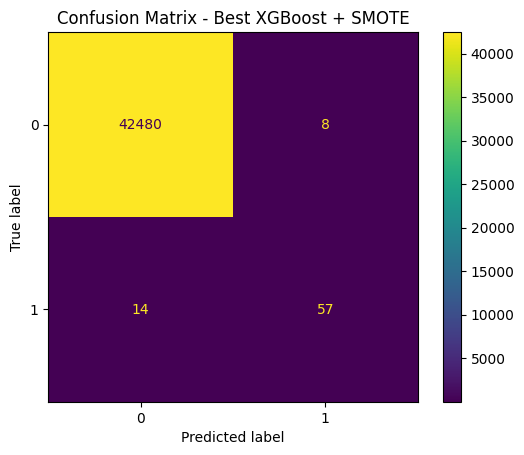

In [ ]:
ConfusionMatrixDisplay(confusion_matrix=cm).plot()
plt.title("Confusion Matrix - Best XGBoost + SMOTE")
plt.show()

### Inference
- The model correctly predicted 42,480 negative cases as negative.
- The model predicted 8 cases as positive when they were actually negative.
  - That is very low.
  - This explains our high precision of 87%. There are not many false alarms here.
- The model predicted 14 cases as negative even though they were actually positive.
  - These are the cases our model `missed`.
- The model correctly identifies 57 Positive cases.
```text
Actual positive cases = 71

Correctly detected     = 57
Missed                 = 14
```
- And
```text
Actual negative cases = 42,488

Correctly rejected     = 42,480
False alarms           = 8
```


2. Precision-Recall Curve

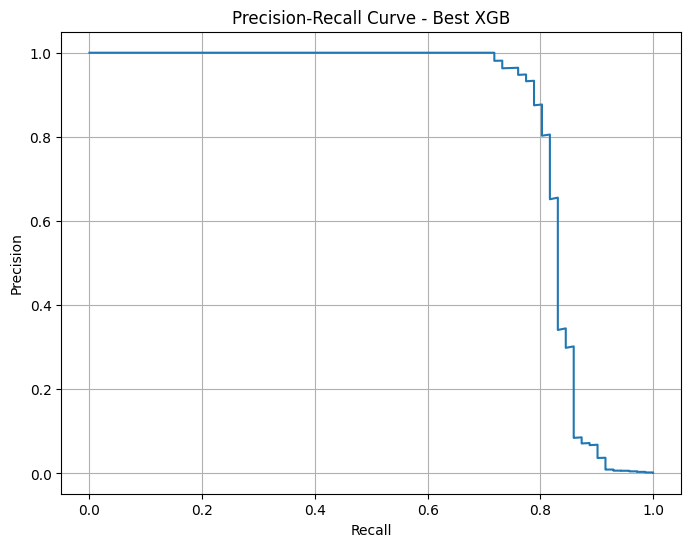

In [ ]:
# Precision recall curve

from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision, recall, thresholds = precision_recall_curve(
    y_val,
    best_xgb_y_val_prob
)

plt.figure(figsize=(8,6))
plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Best XGB")
plt.grid()
plt.show()

### Inference - PR-Curve

For the **XGBoost + SMOTE** model on the validation set:

* **PR-AUC / Average Precision:** **83.2%**
* The curve shows a clear **precision–recall trade-off**:

  * At lower thresholds, recall increases, but precision decreases.
  * At higher thresholds, precision increases, but recall decreases.
* Around the default **0.50 threshold**:

  * **Precision:** 87.69%
  * **Recall:** 80.28%
  * **F1:** 83.82%
* At **0.80 threshold**:

  * **Precision:** 93.33%
  * **Recall:** 78.87%
  * **F1:** 85.50%

### Interpretation

The model maintains **high precision while achieving reasonably high recall**, which is important for this highly imbalanced dataset. The **83.2% PR-AUC** indicates that the model has good ability to distinguish the positive class across different classification thresholds.

The threshold analysis also showed that increasing the threshold from **0.50 → 0.80** improves precision and F1, but slightly reduces recall.

Since you decided to **freeze the model at the 0.50 threshold**, the PR-curve analysis is treated as a **diagnostic**, not a reason to modify the model.

3. Thresholds

In [ ]:
# Threshold analysis

import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds_to_check = np.arange(0.10, 0.91, 0.05)

results = []

for threshold in thresholds_to_check:
  y_pred_threshold = (best_xgb_y_val_prob >= threshold).astype(int)

  results.append({
      "Threshold": threshold,
      "Precision": precision_score(y_val, y_pred_threshold),
      "Recall": recall_score(y_val, y_pred_threshold),
      "F1": f1_score(y_val, y_pred_threshold)
  })


In [ ]:
import pandas as pd

threshold_results = pd.DataFrame(results)

print(threshold_results)

    Threshold  Precision    Recall        F1
0        0.10   0.517544  0.830986  0.637838
1        0.15   0.578431  0.830986  0.682081
2        0.20   0.651685  0.816901  0.725000
3        0.25   0.707317  0.816901  0.758170
4        0.30   0.743590  0.816901  0.778523
5        0.35   0.783784  0.816901  0.800000
6        0.40   0.814286  0.802817  0.808511
7        0.45   0.850746  0.802817  0.826087
8        0.50   0.876923  0.802817  0.838235
9        0.55   0.875000  0.788732  0.829630
10       0.60   0.875000  0.788732  0.829630
11       0.65   0.888889  0.788732  0.835821
12       0.70   0.888889  0.788732  0.835821
13       0.75   0.918033  0.788732  0.848485
14       0.80   0.933333  0.788732  0.854962
15       0.85   0.948276  0.774648  0.852713
16       0.90   0.948276  0.774648  0.852713


### Inference - Threshold Analysis

The threshold analysis showed the following pattern:

| Threshold |  Precision |     Recall |         F1 |
| --------: | ---------: | ---------: | ---------: |
|      0.10 |     51.75% |     83.10% |     63.78% |
|      0.20 |     65.17% |     81.69% |     72.50% |
|      0.30 |     74.36% |     81.69% |     77.85% |
|      0.40 |     81.43% |     80.28% |     80.85% |
|  **0.50** | **87.69%** | **80.28%** | **83.82%** |
|      0.60 |     87.50% |     78.87% |     82.96% |
|      0.70 |     88.89% |     78.87% |     83.58% |
|  **0.80** | **93.33%** | **78.87%** | **85.50%** |
|      0.90 |     94.83% |     77.46% |     85.27% |

### Key findings

* **Lower thresholds (0.10–0.30):** Higher recall but substantially lower precision.
* **Middle thresholds (0.40–0.70):** Better balance between precision and recall.
* **Threshold 0.50:** Gives **87.69% precision, 80.28% recall, and 83.82% F1**.
* **Threshold 0.80:** Gives the highest F1 among the tested thresholds (**85.50%**) and much higher precision (**93.33%**), but recall falls to **78.87%**.
* **Threshold 0.90:** Precision increases further, but recall decreases.

### Final decision

You chose to **freeze the model at the 0.50 threshold** rather than tune the threshold based on this validation analysis.

So the threshold analysis demonstrates that:

> **Increasing the threshold makes the model more conservative: it predicts fewer positives, resulting in higher precision but lower recall.** At 0.50, the model provides a reasonable balance between catching positive cases and avoiding false positives.


4. Feature Importance

In [ ]:
xgb_model = best_xgb.named_steps['model']
print(xgb_model)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)


In [ ]:
print(best_xgb.named_steps.keys())

dict_keys(['smote', 'model'])


In [ ]:
feature_importance = xgb_model.feature_importances_

In [ ]:
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": feature_importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

   Feature  Importance
14     V14    0.606238
10     V10    0.061739
4       V4    0.049638
12     V12    0.046206
17     V17    0.038183
3       V3    0.020237
8       V8    0.016049
9       V9    0.013649
1       V1    0.012653
11     V11    0.011329
29  Amount    0.009735
22     V22    0.009464
19     V19    0.008960
25     V25    0.007937
15     V15    0.007897
21     V21    0.007401
16     V16    0.007180
2       V2    0.006845
5       V5    0.006761
23     V23    0.006289
7       V7    0.006154
13     V13    0.005449
18     V18    0.005139
0     Time    0.005086
6       V6    0.004666
24     V24    0.004383
20     V20    0.004337
28     V28    0.003753
26     V26    0.003489
27     V27    0.003156


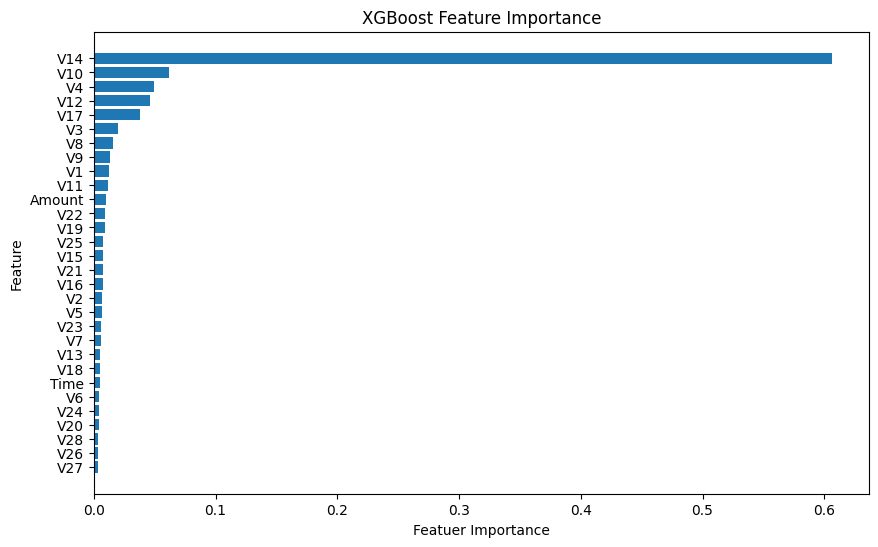

In [ ]:
plt.figure(figsize=(10,6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Featuer Importance")
plt.ylabel("Feature")
plt.title("XGBoost Feature Importance")
plt.gca().invert_yaxis()

plt.show()

### Inference - Feature Importance

The feature-importance analysis using both **XGBoost's built-in importance** and **permutation importance** produced the following key findings:

* **V14 was the most influential feature by a large margin.**

  * It had the highest built-in feature importance.
  * Permuting V14 caused the largest decrease in validation **Average Precision (PR-AUC)**, around **0.30**.
* **V4 was the second most influential feature** according to permutation importance, with an AP decrease of approximately **0.15**.
* Other relatively important features included:

  * **V12** → AP decrease ≈ **0.047**
  * **V3** → AP decrease ≈ **0.034**
  * **V11** → AP decrease ≈ **0.030**
* Several other features had **very small or near-zero permutation importance**, suggesting that removing/shuffling them had little effect on validation PR-AUC.
* **V10** showed relatively high importance in the XGBoost built-in importance plot but considerably lower permutation importance. This can happen when features contain **redundant/correlated information**.

### Overall conclusion

> **V14 is the dominant predictive feature, followed by V4, while V12, V3, and V11 provide additional predictive information. The agreement between built-in and permutation importance strengthens the evidence that V14 is genuinely important to the model's predictions.**

The feature-importance analysis did **not reveal an obvious feature that should be removed**, so the model was kept frozen before moving to the final test-set evaluation.


5. Permutation Importance

In [ ]:
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    best_xgb,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

In [ ]:
perm_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance_Mean": perm_importance.importances_mean,
    "Importance_STD": perm_importance.importances_std
})

perm_df = perm_df.sort_values(
    by="Importance_Mean",
    ascending=False
)

print(perm_df)

   Feature  Importance_Mean  Importance_STD
14     V14         0.302043        0.031812
4       V4         0.148802        0.026155
12     V12         0.047088        0.014655
3       V3         0.034476        0.006957
11     V11         0.030698        0.011919
26     V26         0.019209        0.005621
7       V7         0.016216        0.003354
27     V27         0.009970        0.001839
17     V17         0.006650        0.007032
9       V9         0.006321        0.003883
10     V10         0.006003        0.003619
2       V2         0.005687        0.001925
15     V15         0.005575        0.004711
8       V8         0.004346        0.005228
18     V18         0.003875        0.001561
24     V24         0.003726        0.002049
28     V28         0.003640        0.001603
16     V16         0.003098        0.003202
25     V25         0.002861        0.002229
6       V6         0.002743        0.001693
21     V21         0.002482        0.002125
29  Amount         0.002283     

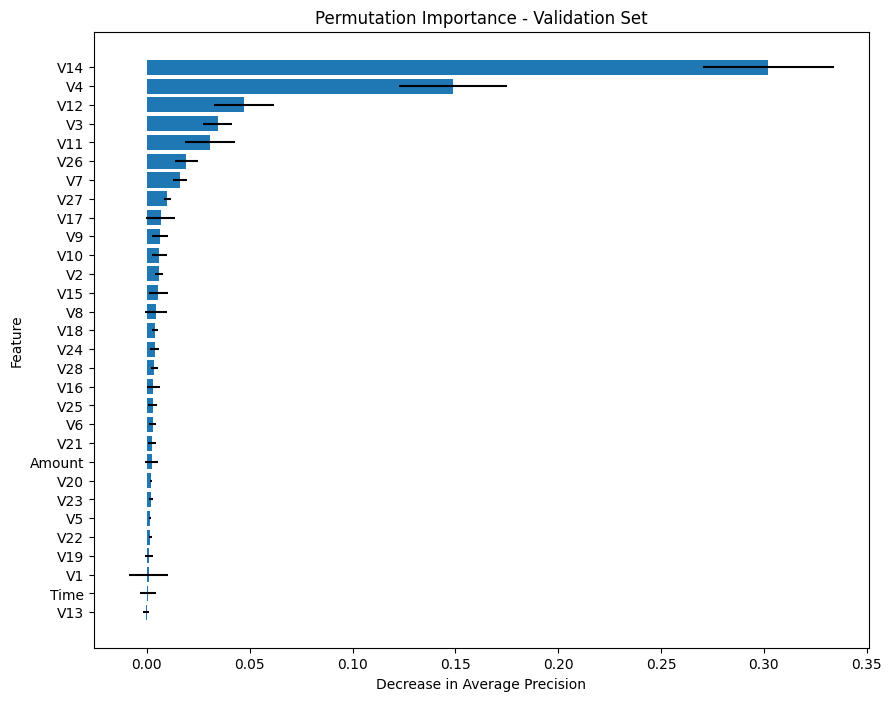

In [ ]:
plt.figure(figsize=(10, 8))

plt.barh(
    perm_df["Feature"],
    perm_df["Importance_Mean"],
    xerr=perm_df["Importance_STD"]
)

plt.xlabel("Decrease in Average Precision")
plt.ylabel("Feature")
plt.title("Permutation Importance - Validation Set")
plt.gca().invert_yaxis()

plt.show()

### Inference - Permutation Importance

Permutation importance was calculated using **Average Precision (PR-AUC)** on the validation set. It measures how much the model's performance decreases when each feature is randomly shuffled.

| Feature        | Approx. decrease in AP | Interpretation                  |
| -------------- | ---------------------: | ------------------------------- |
| **V14**        |               **0.30** | Dominant feature                |
| **V4**         |               **0.15** | Highly important                |
| **V12**        |              **0.047** | Moderately important            |
| **V3**         |              **0.034** | Some contribution               |
| **V11**        |              **0.030** | Some contribution               |
| Other features |                 Near 0 | Limited individual contribution |

### Key findings

* **V14 is by far the most important feature**. Shuffling it caused the largest drop in Average Precision.
* **V4 is the second most important feature**, with a substantial performance drop when permuted.
* **V12, V3, and V11** contribute to the model but to a much smaller extent.
* Many remaining features had **very small or near-zero importance**, meaning the model's PR-AUC did not change much when they were shuffled.
* The results suggest that the model's predictive performance is **heavily driven by a small number of features**, particularly V14 and V4.

### Final conclusion

> **Permutation importance confirms that V14 and V4 are the primary contributors to the model's predictive performance, while V12, V3, and V11 provide smaller supporting contributions.**

This was a **diagnostic result**, not a reason to remove the low-importance features, so the model remained frozen before final testing.


6. Error Analysis

- We are investigating:
1. 14 false Negatives
2. 8 False Positives

In [ ]:
import numpy as np
import pandas as pd

# Predictions
y_val_pred = best_xgb.predict(X_val)
y_val_proba = best_xgb.predict_proba(X_val)[:, 1]

# Convert y_val to NumPy array to avoid index-alignment issues
y_val_array = np.asarray(y_val)
y_val_pred_array = np.asarray(y_val_pred)

# Create masks
fn_mask = (y_val_array == 1) & (y_val_pred_array == 0)
fp_mask = (y_val_array == 0) & (y_val_pred_array == 1)

# Extract false negatives and false positives
false_negatives = X_val.loc[fn_mask].copy()
false_positives = X_val.loc[fp_mask].copy()

# Add predicted probabilities
false_negatives["predicted_probability"] = y_val_proba[fn_mask]
false_positives["predicted_probability"] = y_val_proba[fp_mask]

print("False Negatives:", len(false_negatives))
print("False Positives:", len(false_positives))

print("\nFALSE NEGATIVES")
display(false_negatives)

print("\nFALSE POSITIVES")
display(false_positives)

False Negatives: 14
False Positives: 8

FALSE NEGATIVES


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,predicted_probability
274382,165981.0,-5.766879,-8.402154,0.056543,6.950983,9.880564,-5.773192,-5.748879,0.721743,-1.076274,...,0.880395,-0.130436,2.241471,0.665346,-1.890041,-0.120803,0.073269,0.583799,0.00,1.211064e-05
93788,64585.0,1.080433,0.962831,-0.278065,2.743318,0.412364,-0.320778,0.041290,0.176170,-0.966952,...,-0.008996,-0.057036,-0.053692,-0.026373,0.400300,0.072828,0.027043,0.063238,0.00,1.996042e-01
29687,35585.0,-2.019001,1.491270,0.005222,0.817253,0.973252,-0.639268,-0.974073,-3.146929,-0.003159,...,2.839596,-1.185443,-0.142812,-0.086103,-0.329113,0.523601,0.626283,0.152440,0.76,1.723404e-03
56703,47545.0,1.176716,0.557091,-0.490800,0.756424,0.249192,-0.781871,0.228750,-0.040840,-0.432111,...,-0.062166,-0.128168,-0.040176,0.110040,0.437891,0.368809,-0.018287,0.031173,0.76,2.217622e-05
229730,146026.0,1.894036,1.905806,-3.515730,4.508913,2.044466,-1.420468,1.057480,-0.281157,-1.832604,...,-0.144713,-0.310108,-0.101530,-0.414960,0.376597,0.150778,-0.013712,0.048084,2.22,3.709633e-02
58761,48533.0,1.243848,0.524526,-0.538884,1.209196,0.479538,-0.197429,0.049166,0.037792,0.128119,...,-0.051660,-0.084089,-0.192846,-0.917392,0.681953,-0.194419,0.045917,0.040136,1.00,2.568531e-05
131272,79540.0,-0.114361,1.036129,1.984405,3.128243,-0.740344,1.548619,-1.701284,-2.203842,-1.242265,...,-1.032935,1.196428,-0.112857,0.254719,0.696668,0.482370,0.129969,0.223924,0.20,5.233719e-06
52521,45501.0,1.001992,0.047938,-0.349002,1.493958,0.186939,0.190966,-0.001112,0.147140,0.580415,...,-0.334417,-1.014315,-0.128427,-0.946242,0.456090,-0.453206,0.046627,0.064698,105.99,6.180863e-04
68633,53076.0,1.296231,0.417447,0.193963,0.901644,0.130531,-0.371634,0.158126,-0.202669,-0.079512,...,-0.112114,-0.220002,-0.121022,-0.440454,0.671540,-0.413518,0.032838,0.020600,1.18,8.863192e-07
68067,52814.0,-1.101847,-1.632441,0.901067,0.847753,-1.249091,0.654937,1.448868,0.023308,-0.136742,...,0.610654,0.835795,1.179955,-0.029091,-0.300896,0.699175,-0.336072,-0.177587,519.90,1.949266e-03



FALSE POSITIVES


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,predicted_probability
124300,77248.0,1.155680,-0.762376,-0.364771,-0.593877,-0.521737,-0.239822,-0.389564,-0.049162,-0.887006,...,-0.002109,-0.291189,-0.242909,-0.556800,0.519254,-0.281754,-0.005183,0.042440,140.58,0.710677
192731,129828.0,-0.873133,2.775615,-1.973345,4.780013,0.793661,1.201479,-0.715422,-1.011743,-0.995095,...,1.587643,-0.543435,0.282200,-0.109539,-0.226854,0.407486,-0.811602,-0.049674,7.57,0.784898
172818,121251.0,-0.461571,3.140351,-2.752211,3.580295,3.243804,-1.462513,1.979739,-0.040094,-2.635506,...,-0.248399,-0.903682,-0.468425,-1.168654,0.091457,0.057969,0.142405,0.300641,10.61,0.956830
220567,142223.0,1.719332,1.028017,-2.056034,4.206490,1.101320,-0.713744,0.672316,-0.140571,-1.506492,...,-0.212753,-0.766599,0.117322,-0.242448,-0.108112,-0.207626,-0.031489,0.022199,83.40,0.642577
52398,45430.0,-1.614368,1.480449,0.403981,1.217286,-0.489909,-0.975800,-1.005418,0.433922,-0.937126,...,0.336746,0.270269,-0.231943,0.588405,0.193725,-0.485591,0.669115,0.349551,2.00,0.994254
114902,73667.0,-3.423854,1.579438,-1.338452,1.012327,-1.363651,-1.063367,-1.643178,0.783429,-0.356442,...,0.002688,-0.683665,0.209910,-0.031626,-0.071505,0.048280,-0.225216,-0.189759,8.99,0.975179
187657,127631.0,1.813886,0.381837,-4.023519,1.046436,1.584362,-0.344732,0.177102,0.088170,1.196258,...,-0.007837,0.159248,-0.439455,-0.861765,0.653695,-0.187299,0.064843,0.069528,107.50,0.835894
239473,150125.0,-6.446779,-4.148933,-2.467936,3.579053,1.280263,-1.649037,-4.066319,0.984977,-0.289895,...,-0.342282,-1.340772,-2.174765,0.271926,-1.403307,0.183721,0.151710,0.434945,1.00,0.736120


In [ ]:
print("False Negative probabilities:")
print(false_negatives["predicted_probability"].describe())

print("\nFalse Positive probabilities:")
print(false_positives["predicted_probability"].describe())

False Negative probabilities:
count    1.400000e+01
mean     4.508800e-02
std      1.049567e-01
min      8.863192e-07
25%      2.305349e-05
50%      1.170745e-03
75%      2.121459e-02
max      3.601165e-01
Name: predicted_probability, dtype: float64

False Positive probabilities:
count    8.000000
mean     0.829554
std      0.133303
min      0.642577
25%      0.729759
50%      0.810396
75%      0.961417
max      0.994254
Name: predicted_probability, dtype: float64


In [ ]:
important_features = ["V14", "V4", "V12", "V3", "V11"]

print("FALSE NEGATIVES")
display(false_negatives[important_features + ["predicted_probability"]])

print("\nFALSE POSITIVES")
display(false_positives[important_features + ["predicted_probability"]])

FALSE NEGATIVES


,V14,V4,V12,V3,V11,predicted_probability
274382,0.984344,6.950983,-0.050468,0.056543,-1.475145,1.211064e-05
93788,-1.880275,2.743318,-0.276309,-0.278065,2.140057,1.996042e-01
29687,-0.895434,0.817253,-1.073812,0.005222,0.024370,1.723404e-03
56703,-1.043705,0.756424,0.654567,-0.490800,2.281939,2.217622e-05
229730,-4.942612,4.508913,-0.741088,-3.515730,2.220795,3.709633e-02
58761,-0.994581,1.209196,-0.818804,-0.538884,-0.668359,2.568531e-05
131272,0.521484,3.128243,0.933216,1.984405,1.293418,5.233719e-06
52521,-1.381214,1.493958,-0.567380,-0.349002,-0.984172,6.180863e-04
68633,-0.007791,0.901644,0.687488,0.193963,-0.876738,8.863192e-07
68067,0.578869,0.847753,-0.795988,0.901067,1.172355,1.949266e-03



FALSE POSITIVES


,V14,V4,V12,V3,V11,predicted_probability
124300,-1.238474,-0.593877,-0.029673,-0.364771,0.865752,0.710677
192731,-2.654680,4.780013,-0.967064,-1.973345,0.594267,0.784898
172818,-6.754423,3.580295,-3.012751,-2.752211,2.163028,0.956830
220567,-2.541002,4.206490,-0.068217,-2.056034,1.531470,0.642577
52398,-2.673533,1.217286,-1.905454,0.403981,1.096572,0.994254
114902,-3.099716,1.012327,-3.452937,-1.338452,1.298497,0.975179
187657,-5.553603,1.046436,-0.823528,-4.023519,0.950934,0.835894
239473,-2.102828,3.579053,-2.135399,-2.467936,-0.186338,0.736120


### Inference - Error Analysis

The error analysis was performed on the **validation set** using the frozen XGBoost + SMOTE model at the **0.50 threshold**.

#### Error distribution

* **False Negatives (FN): 14**

  * Actual positive cases incorrectly predicted as negative.
* **False Positives (FP): 8**

  * Actual negative cases incorrectly predicted as positive.

#### False Negative analysis

The predicted probabilities for the 14 FNs were:

* **Mean:** 0.045
* **Median:** 0.00117
* **Maximum:** 0.360
* Most FNs had **very low predicted probabilities**.

This means most of the false negatives were **not borderline cases**. The model was often quite confident that these observations belonged to the negative class.

#### False Positive analysis

For the 8 FPs:

* **Mean predicted probability:** 0.830
* **Median:** 0.810
* **Minimum:** 0.643
* **Maximum:** 0.994

The model was therefore also fairly confident about many of its false-positive predictions.

### Key conclusion

> **The remaining errors are not primarily a simple threshold problem.** Most FNs were confidently classified as negative, while FPs were often confidently classified as positive.

This suggests that the remaining errors may be related to things such as **overlapping class characteristics, limited predictive information, data/label noise, or difficult observations** rather than simply choosing a different threshold.

Therefore, no obvious corrective action was identified from the error analysis, and the model was **frozen before proceeding to the final test-set evaluation**.


### Final Test-Set Performance

In [ ]:
final_test_pred = best_xgb.predict(X_test)
final_test_prob = best_xgb.predict_proba(X_test)[:, 1]

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

print("=" * 70)
print("FINAL TEST SET EVALUATION - XGBoost + SMOTE")
print("=" * 70)

print(f"Accuracy:       {accuracy_score(y_test, final_test_pred):.4f}")
print(f"Precision:      {precision_score(y_test, final_test_pred):.4f}")
print(f"Recall:         {recall_score(y_test, final_test_pred):.4f}")
print(f"F1:             {f1_score(y_test, final_test_pred):.4f}")
print(f"ROC-AUC:        {roc_auc_score(y_test, final_test_prob):.4f}")
print(f"PR-AUC:         {average_precision_score(y_test, final_test_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_test_pred))

FINAL TEST SET EVALUATION - XGBoost + SMOTE
Accuracy:       0.9994
Precision:      0.8333
Recall:         0.7746
F1:             0.8029
ROC-AUC:        0.9568
PR-AUC:         0.7897

Confusion Matrix:
[[42477    11]
 [   16    55]]


Yes — these are your **final test-set results**, and now we can assess the model's final generalization performance.

### Final Test Set Results

| Metric     | Test Result |
| ---------- | ----------: |
| Accuracy   |  **99.94%** |
| Precision  |  **83.33%** |
| Recall     |  **77.46%** |
| F1-score   |  **80.29%** |
| ROC-AUC    |  **95.68%** |
| **PR-AUC** |  **78.97%** |

Confusion matrix:

```text
[[42477    11]
 [   16    55]]
```

Therefore:

* **TN = 42,477**
* **FP = 11**
* **FN = 16**
* **TP = 55**

### Comparison Across Stages

| Metric     |     CV | Validation | Final Test |
| ---------- | -----: | ---------: | ---------: |
| **PR-AUC** | 85.38% |     83.20% | **78.97%** |
| Precision  |      — |     87.69% | **83.33%** |
| Recall     |      — |     80.28% | **77.46%** |
| F1         |      — |     83.82% | **80.29%** |
| ROC-AUC    |      — |     96.85% | **95.68%** |

### Interpretation

The model performs **slightly worse on the unseen test set than on the validation set**.

The most important difference is:

**Validation PR-AUC → 83.20%**
**Test PR-AUC → 78.97%**

That's a drop of about **4.23 percentage points**.

Similarly:

* Precision decreased from **87.69% → 83.33%**
* Recall decreased from **80.28% → 77.46%**
* F1 decreased from **83.82% → 80.29%**
* ROC-AUC decreased from **96.85% → 95.68%**

This indicates some difference between validation and test performance, but the model still maintains **strong discrimination** on completely unseen data.

### Confusion Matrix Interpretation

Out of the **42,559 test observations**:

* The model correctly classified **42,477 negatives**.
* It incorrectly classified **11 negatives as positive**.
* It missed **16 actual positives**.
* It correctly detected **55 positives**.

The particularly important numbers for your imbalanced problem are therefore:

> **55/71 positive cases detected → 77.46% recall**

and

> **55/(55+11) predicted positives were actually positive → 83.33% precision**

### Final conclusion

Your final frozen XGBoost + SMOTE model achieved:

> **78.97% PR-AUC, 83.33% precision, 77.46% recall, and 80.29% F1 on the completely unseen test set.**

The test result is lower than the validation result, particularly in PR-AUC, so the validation performance was somewhat optimistic. However, the model still demonstrates **strong performance on the unseen test data**, especially considering the severe class imbalance.


### Next Steps:
- Train other potential candidates like Random Forest, Random Forest with Class weights and SMOTE or maybe SVMs to test whether we can get better performing models.

### Disclaimer:
- Some of the inference statements were taken from a gpt just for the sake of better wording and tone of explanation.